# Segundo Examen Parcial - Control Difuso y Algoritmos Geneticos

 *Optimización Multiobjetivo de Sistemas Difusos mediante Algoritmos Geneticos con **PyGAD*** 

### **Objetivo**

Utilizar la biblioteca pyGAD para optimizar automáticamente sistemas de inferencia difusa tipo Mamdani empleados para el control de un servomotor de corriente directa.


#### Importaciones

In [43]:
import time
import timeit

import matplotlib.pyplot as plt
import numpy as np
import pygad
import skfuzzy as fuzz
from scipy.signal import lsim, lti, square
from skfuzzy import control as ctrl


#### Constantes obligatorias

In [44]:
# Universos de discurso
ERROR_MIN, ERROR_MAX = -np.pi/2, np.pi/2
DERROR_MIN, DERROR_MAX = -np.pi/6, np.pi/6
VOLTAGE_MIN, VOLTAGE_MAX = -8.18, 8.18
N_PUNTOS_UNIVERSO = 1000

# Simulación obligatoria
T_SIM = 200       # segundos
PERIODO = 100     # segundos, referencia cuadrada ±1 rad, ciclo útil 50 %

DT_REFERENCIA = 0.1

TR0 = 9      # segundos
TS0 = 13     # segundos

### **Fase 1:** Implementación de los controladores base

- Controlador A. Sistema difuso con: **5 términos lingüísticos por entrada** (generados con automf)
- Controlador B. Sistema difuso con: **7 términos lingüísticos por entrada** (generados con automf)
- Controlador C. Sistema difuso con: **9 términos lingüísticos por entrada** (generados con automf) 

Cada variable tiene N términos generados con `automf` y la base usa todas las reglas (N² reglas).
`automf` solo trae nombres para 3, 5 y 7 términos, por eso se pasan los nombres explícitos.

#### Planta, tiempo y referencia

In [45]:
G = lti([0.5], [1, 13.6667, 23.3487, 0])

dt = DT_REFERENCIA
t = np.arange(0, T_SIM + dt, dt)

r = square(2*np.pi*t/PERIODO)

x0 = [0, 0, 0]

In [46]:
def crear_controlador(nombres):
    n = len(nombres)
    error = ctrl.Antecedent(np.linspace(ERROR_MIN, ERROR_MAX, 1000), 'error')
    derror = ctrl.Antecedent(np.linspace(DERROR_MIN, DERROR_MAX, 1000), 'derror')
    voltage = ctrl.Consequent(np.linspace(VOLTAGE_MIN, VOLTAGE_MAX, 1000), 'voltage')
    for variable in (error, derror, voltage):
        variable.automf(n, names=nombres)

    reglas = []
    for i in range(n):
        for j in range(n):
            k = i if i != n // 2 else j
            reglas.append(ctrl.Rule(error[nombres[i]] & derror[nombres[j]], voltage[nombres[k]]))
    return ctrl.ControlSystemSimulation(ctrl.ControlSystem(reglas))

controller_A = crear_controlador(['NB', 'NS', 'ZE', 'PS', 'PB'])
controller_B = crear_controlador(['NB', 'NM', 'NS', 'ZE', 'PS', 'PM', 'PB'])
controller_C = crear_controlador(['NVB', 'NB', 'NM', 'NS', 'ZE', 'PS', 'PM', 'PB', 'PVB'])

#### Funciones de membresia generadas por `automf`

##### Controlador A

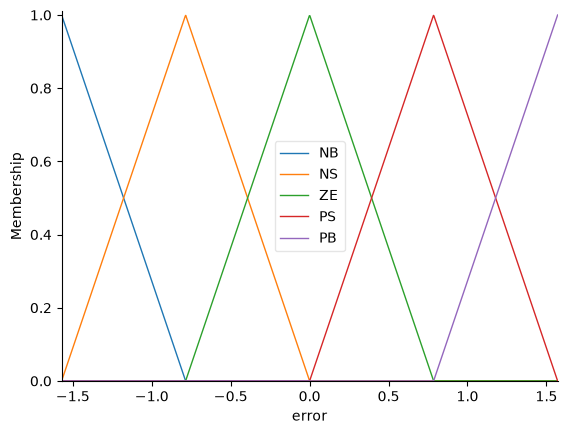

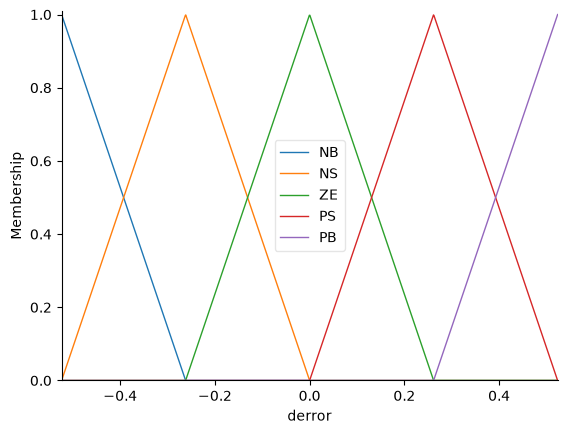

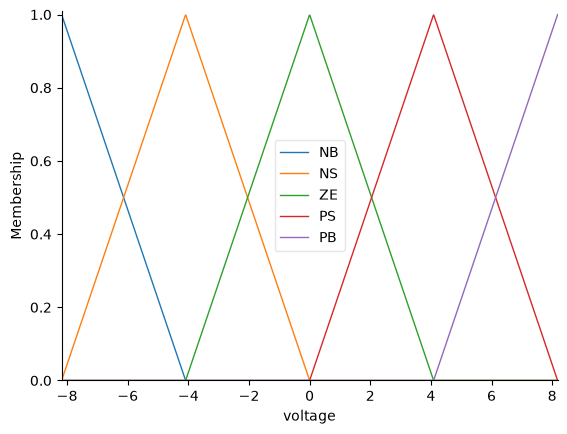

In [47]:
for variable in list(controller_A.ctrl.antecedents) + list(controller_A.ctrl.consequents):
    variable.view()

#### Simulación del lazo cerrado
En lazo cerrado el voltaje *$u$* depende de *$theta$*, así que no se puede llamar a `lsim` una sola vez con todo *$u$*.
Se llama a `lsim` en cada intervalo con el voltaje *$u_k$* constante y *$x_0$* igual al estado final del intervalo anterior. `lsim` toma *$x_0$* como el estado en $t = 0$, por eso cada intervalo se simula con `T = t[:2] = [0, dt]` y no con el tiempo absoluto del intervalo.

Con `dt = 0.01 s` cada simulación de 200 s hace 20 000 inferencias difusas; simular los tres controladores tarda unos 20 minutos.

In [48]:
def paso_planta(u, t, x0):
    tout, theta, xout = lsim(G, U=u, T=t, X0=x0)
    return theta[-1], xout[-1]

def simular(controller):
    theta = np.zeros(len(t))
    u = np.zeros(len(t))
    tiempos = []
    x = x0
    for k in range(len(t) - 1):
        e = r[:k+1] - theta[:k+1]
        de = np.diff(e, prepend=e[0]) / dt
        controller.input['error'] = e[-1]
        controller.input['derror'] = de[-1]
        start = time.perf_counter()
        controller.compute()
        end = time.perf_counter()
        inference_time = end - start
        tiempos.append(inference_time)
        u[k] = controller.output['voltage']
        theta[k+1], x = paso_planta([u[k], u[k]], t[:2], x)
    return theta, u, np.mean(tiempos)

#### Métricas de desempeño y fitness

Solo se evalúan la transición positiva ($−1 \rightarrow +1$, de 100 a 150 s) y la negativa ($+1 \rightarrow -1$, de 50 a 100 s); el resto de la simulación se descarta.

- **OS (%)**: lo que la respuesta sobresale de la referencia, en % de $|r| = 1 rad$.
- **$t_r$ (s)**: tiempo entre el 10 % y el 90 % de la excursión de la propia respuesta (Figura 5 del artículo).
- **$t_s$(s)**: tiempo desde el cambio de referencia hasta que $|e|$ queda por debajo del 5 % de la referencia (0.05 rad) sin volver a salir de esa banda.
- **SSE (rad)**: promedio del error, con signo, desde $t_s$ hasta el siguiente cambio de referencia.
- **q** (Ec. 13): global sobre los 200 s y la misma en ambas transiciones.
- **Pesos**: iguales, w = 1/8. Las ocho métricas tienen la misma importancia, como en el artículo.

In [55]:
w = [1/8] * 8

def medir_transicion(theta, t_cambio, t_siguiente):
    i0, i1 = round(t_cambio / dt), round(t_siguiente / dt)
    th = theta[i0:i1]                    # respuesta entre dos cambios de referencia
    tv = t[i0:i1] - t[i0]                # tiempo medido desde el cambio de referencia
    ref = r[i0]                          # nuevo nivel de la referencia (+1 o -1)
    e = ref - th

    # Sobreimpulso (%): lo que sobresale respecto de la referencia
    OS = 100 * max(0, np.max(ref * (th - ref)))

    # Tiempo de crecimiento: del 10 % al 90 % de la excursión de la propia respuesta
    inicio, final = th[0], th[-1]
    sentido = np.sign(final - inicio)
    if sentido == 0:
        tr = np.inf
    else:
        nivel10 = inicio + 0.1 * (final - inicio)
        nivel90 = inicio + 0.9 * (final - inicio)
        tr = tv[np.argmax(sentido * (th - nivel90) >= 0)] - tv[np.argmax(sentido * (th - nivel10) >= 0)]

    # Tiempo de establecimiento: después de la última muestra con |e| >= 0.05 rad
    fuera = np.nonzero(np.abs(e) >= 0.05)[0]
    if len(fuera) == 0 or fuera[-1] == len(e) - 1:
        ts = np.inf
        k = len(e) - round(5 / dt)       # sin t_s: se promedian los últimos 5 s
    else:
        k = fuera[-1] + 1
        ts = tv[k]

    # Error en estado estable: promedio del error (con signo) después de t_s
    SSE = np.mean(e[k:])
    return OS, SSE, tr, ts

def factor_q(theta):
    if theta.min() >= r.min() and theta.max() <= r.max():      # la respuesta no se sale del rango de la referencia
        return (r.max() - theta.min()) / (theta.max() - theta.min())
    return 1.0

def evaluar(theta):
    OS_pos, SSE_pos, tr_pos, ts_pos = medir_transicion(theta, 100, 150)    # transición positiva
    OS_neg, SSE_neg, tr_neg, ts_neg = medir_transicion(theta, 50, 100)     # transición negativa
    q = factor_q(theta)
    fitness = (w[0] / (1 + abs(OS_pos)) + w[1] / (1 + abs(SSE_pos)) + w[2] * TR0 / (q * tr_pos) + w[3] * TS0 / ts_pos
               + w[4] / (1 + abs(OS_neg)) + w[5] / (1 + abs(SSE_neg)) + w[6] * TR0 / (q * tr_neg) + w[7] * TS0 / ts_neg)
    return {'OS+': OS_pos, 'OS-': OS_neg, 'SSE+': SSE_pos, 'SSE-': SSE_neg,
            'tr+': tr_pos, 'tr-': tr_neg, 'ts+': ts_pos, 'ts-': ts_neg, 'q': q, 'fitness': fitness}

#### Simulación de los controladores base

In [50]:
controladores = {'A': controller_A, 'B': controller_B, 'C': controller_C}
resultados = {}
for nombre, controller in controladores.items():
    theta, u, inference_time = simular(controller)
    resultados[nombre] = {'theta': theta, 'tiempo_inferencia_ms': 1000 * inference_time,
                          'reglas': len(list(controller.ctrl.rules))}

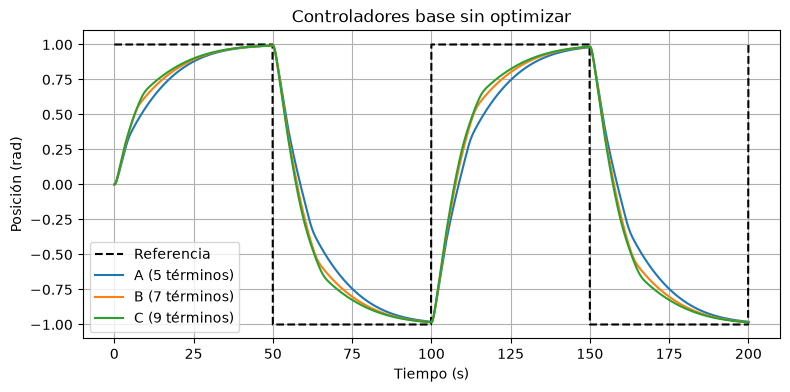

In [51]:
plt.figure(figsize=(9, 4))
plt.plot(t, r, 'k--', label='Referencia')
for nombre, etiqueta in (('A', 'A (5 términos)'), ('B', 'B (7 términos)'), ('C', 'C (9 términos)')):
    plt.plot(t, resultados[nombre]['theta'], label=etiqueta)
plt.xlabel('Tiempo (s)')
plt.ylabel('Posición (rad)')
plt.title('Controladores base sin optimizar')
plt.grid(True)
plt.legend()
plt.show()

#### Registro de métricas de los controladores base sin optimizar

In [54]:
for nombre in resultados:
    resultados[nombre].update(evaluar(resultados[nombre]['theta']))

filas = [('OS+ (%)', 'OS+'), ('OS- (%)', 'OS-'), ('SSE+ (rad)', 'SSE+'), ('SSE- (rad)', 'SSE-'),
         ('tr+ (s)', 'tr+'), ('tr- (s)', 'tr-'), ('ts+ (s)', 'ts+'), ('ts- (s)', 'ts-'), ('q', 'q'),
         ('Fitness total', 'fitness'), ('Reglas totales', 'reglas'), ('Inferencia (ms)', 'tiempo_inferencia_ms')]
print(f"{'Métrica':<18}" + ''.join(f"{'Controlador ' + nombre:>16}" for nombre in resultados))
for etiqueta, clave in filas:
    print(f"{etiqueta:<18}" + ''.join(f"{resultados[nombre][clave]:>16.4f}" for nombre in resultados))

Métrica              Controlador A   Controlador B   Controlador C
OS+ (%)                     0.0000          0.0000          0.0000
OS- (%)                     0.0000          0.0000          0.0000
SSE+ (rad)                  0.0327          0.0301          0.0295
SSE- (rad)                 -0.0328         -0.0303         -0.0296
tr+ (s)                    24.9000         22.3000         20.7000
tr- (s)                    25.0000         22.3000         20.7000
ts+ (s)                    41.6000         39.7000         38.9000
ts- (s)                    41.7000         39.7000         38.9000
q                           1.0040          1.0037          1.0036
Fitness total               0.6599          0.6751          0.6847
Reglas totales             25.0000         49.0000         81.0000
Inferencia (ms)             8.2703         20.0711         39.5604


### **Fase 2:** Optimización mediante **PyGAD**

- 20 individuos
- 30 generaciones

### **Fase 3:** Selección del mejor individuo

- el mejor individuo del sistema de 5 términos;
- el mejor individuo del sistema de 7 términos;
- el mejor individuo del sistema de 9 términos.

### **Fase 4:** Evaluación del costo computacional

- **Tiempo total de optimización:** Tiempo requerido para completar todas las generaciones del algoritmo genético.
- **Tiempo promedio de inferencia:** Tiempo promedio requerido para generar una salida del controlador difuso.
- **Número de parámetros optimizados:** Cantidad total de genes presentes en el cromosoma.
- **El número y exactamente qué reglas quedaron activas:** Cantidad de reglas ﬁnalmente utilizadas por la mejor solución encontrada y además cuáles fueron seleccionadas.
- **Uso de memoria:** Uso aproximado de memoria asociado al controlador obtenido.

### **Fase 5:** Repetibilidad Experimental

Los algoritmos genéticos son métodos estocásticos. Por esta razón, todos los experimentos deben repetirse como mínimo 5 veces utilizando semillas aleatorias distintas.